## 1、多个中间件执行顺序

问题：Middleware 可以叠加使用，那么多个中间件书写顺序重要吗？

非常重要！

比如：
```
middleware=[
    TrimmerMiddleware(), # 1. 先修剪消息
    SummarizationMiddleware(), # 2. 再摘要
    LoggingMiddleware() # 3. 最后记录日志
]
```
```
agent = create_agent(
    model=model,
    tools=[get_weather, get_news],
    middleware=[
        PIIMiddleware(strategy="redact"), # 1. 最先检查PII
        ModelCallLimitMiddleware(run_limit=10), # 2. 限制调用次数
        SummarizationMiddleware(max_tokens_before_summary=500), # 3. 总结历史
        ToolRetryMiddleware(max_retries=3), # 4. 重试工具
    ]
)
```

In [1]:
from langchain.agents import create_agent
from typing import Any
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents.middleware import AgentMiddleware
from langchain.agents.middleware.types import StateT
from langgraph.runtime import Runtime
from langgraph.typing import ContextT


class Middleware1(AgentMiddleware):
    def before_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware1: before model")
        return None

    def after_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware1: after model")
        return None

class Middleware2(AgentMiddleware):
    def before_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware2: before model")
        return None

    def after_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware2: after model")
        return None

class Middleware3(AgentMiddleware):
    def before_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware3: before model")
        return None

    def after_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        print("Middleware3: after model")
        return None

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    tools=[],
    middleware=[Middleware1(), Middleware2(), Middleware3()]
)

print("\n执行一次调用，观察顺序：")
agent.invoke({"messages": [{"role": "user", "content": "测试"}]})


执行一次调用，观察顺序：
Middleware1: before model
Middleware2: before model
Middleware3: before model
Middleware3: after model
Middleware2: after model
Middleware1: after model


{'messages': [HumanMessage(content='测试', additional_kwargs={}, response_metadata={}, id='6776c1f4-da3d-49c9-bca8-0490b0993dc6'),
  AIMessage(content='你好！测试收到，我在正常工作。😊\n\n有什么可以帮\n帮你的吗？无论是回答问题、写作、翻译、编程，还是其他任务，都可以告诉我。', additional_kwargs={'refusal': None, 'reasoning_content': 'The user just said "测试" which means "test" in Chinese. They\'re probably testing if I\'m working. I should respond in Chinese, briefly and helpfully.'}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 31, 'total_tokens': 102, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 35, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 31}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe0

## 2、自定义中间件

某些复杂场景下，官方内置的中间件不能完全满足需求，此时可以通过实现LangChain暴露的中间件hook函数 构建自定义中间件。

说明：尽可能使用内置中间件。

### 2.1 什么是hook函数

Hook 函数，中文常叫 钩子函数 ，指的是：在某个既定流程的特定时机，被框架、系统或主程序 自动调用 的扩展函数。

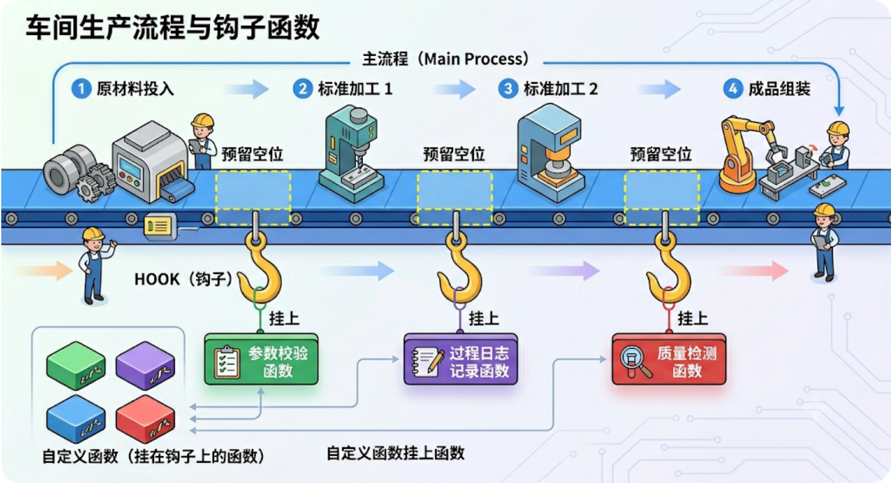

核心特点：

1、不是你主动在业务代码里随便调用的，而是当流程运行到某个“钩子点”时，系统自动触发它。

2、它依附于一个更大的执行流程。比如“请求开始前”“模型调用前”“任务结束后”“异常发生时”等。

3、它的作用是让你在不改主流程源码的前提下插入自己的逻辑。例如做 日志 、 鉴权 、 修改输入 、拦截输出 、 清理资源 等。

LangChain的中间件作用在Agent架构中，后者是基于LangGraph构建的流程图。如下列出了六个hook函数（钩子函数）：

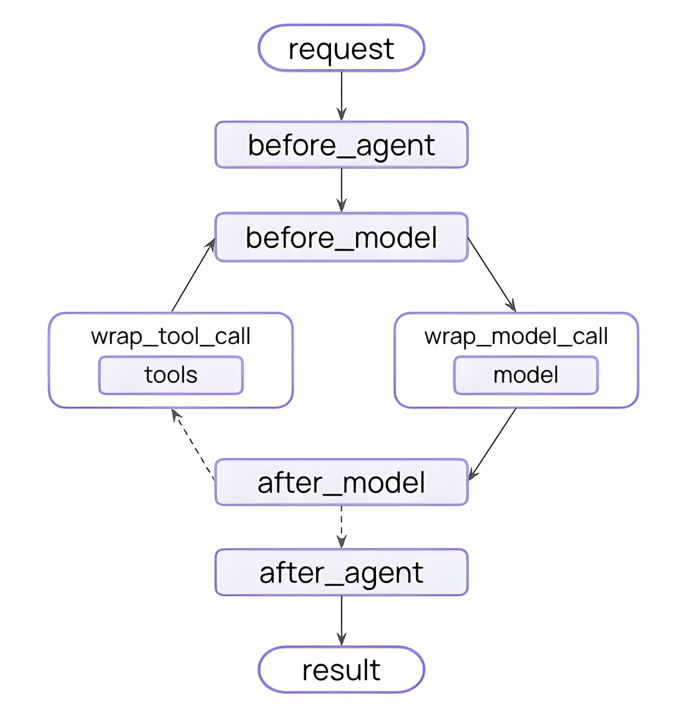

无论是官方内置中间件、自定义中间件、还是下文提到的便捷装饰器中间件，通常都是通过实现其中的一个或多个hook来生效的。

### 2.2 LangChain的hook函数分类

官方将六个钩子函数按照风格分为两类：

类型1:Node-style hooks（节点风格钩子），顾名思义，它们在流程的特定节点运行。适合顺序逻辑，如记录日志、验证。包括：
- before_agent：在Agent开始运行之前执行。
- before_model：在模型调用之前执行。
- after_model：在模型调用之后执行。
- after_agent：在Agent流程全部完成之后执行。

类型2:Wrap-style hooks（包装风格钩子），顾名思义，它们在模型或工具调用前后运行。适合控制流，如重试、回退、缓存。包括：
- wrap_model_call：包裹模型调用。
- wrap_tool_call：包裹工具调用。



### 2.3 Node-style hooks函数用法

支持两种用法：
- 装饰器是函数式挂载，把一个hook快速挂载到Agent的某个节点。
- 类写法是对象化中间件，把中间件封装成一个可配置、可复用、可扩展的组件。

#### 2.3.1 基本用法

1、基于装饰器实现

In [2]:
from langchain_core.messages import HumanMessage
from langchain.agents import create_agent
from typing import Any
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents.middleware import before_model, after_model, before_agent, after_agent
from langchain.agents.middleware.types import StateT
from langgraph.runtime import Runtime
from langgraph.typing import ContextT


load_dotenv(override=True)

@before_model
def before_model_middleware(state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
    state["messages"][-1].content += "-> before_model <-"
    return None

@after_model
def after_model_middleware(state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
    state["messages"][-1].content += "-> after_model <-"
    return None

@before_agent
def before_agent_middleware(state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
    state["messages"][-1].content += "-> before_agent <-"
    return None

@after_agent
def after_agent_middleware(state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
    state["messages"][-1].content += "-> after_agent <-"
    return None

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    tools=[],
    middleware=[before_model_middleware, before_agent_middleware, after_agent_middleware, after_model_middleware]
)

response = agent.invoke({
    "messages": [HumanMessage("你好啊")],
})

for msg in response["messages"]:
    msg.pretty_print()

================================ Human Message =================================

你好啊-> before_agent <--> before_model <-
================================== Ai Message ==================================

你写的像是 **Agent / 中间件生命周期钩子** 的关系：

```text
用户请求
  -> before_agent
      -> before_model
          -> LLM / Model 调用
      -> after_model
      -> 可能需要 Tool
      -> 再进入下一轮 before_model ...
  -> after_agent
```

关键区别：

- **before_agent**：整个 Agent 开始处理一次请求前调用，通常只执行一次。  
  适合做：初始化状态、鉴权、加载上下文、设置本次会话信息。

- **before_model**：每次调用大模型前都会调用，可能在同一请求里执行多次。  
  适合做：裁剪/改写 messages、动态注入 system prompt、按轮次调整上下文、动态选择模型参数。

简单理解：

```text
before_agent：进门一次
before_model：每次问模型前都过一次
```

所以关系不是简单互斥，而是：

```text
before_agent
   └── before_model
          └── model
          └── tools
          └── before_model
                 └── model ...
```

如果你说的是 **LangChain / LangGraph Agent middleware**，这个解释就是对应的。如果你指的是别的框架的 `before_agent` / `before_model`，告诉我框架名，我可以按那个框架给准确说明。-> after_model <--> after_agent <-


2、基于类实现

关键规则：

1、必须继承`AgentMiddleware`。

2、方法名固定(`before_model`，`after_model`)。

3、类名随意。

LangGraph 只看：
- 是否继承 AgentMiddleware？
- 是否有 before_model / after_model 等方法？

In [3]:
from langchain_core.messages import HumanMessage
from langchain.agents import create_agent
from typing import Any
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents.middleware.types import StateT
from langgraph.runtime import Runtime
from langgraph.typing import ContextT

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

class MyMiddleware(AgentMiddleware):
    def __init__(self):
        super().__init__()

    def before_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        state["messages"][-1].content += "-> before_model <-"
        return None

    def after_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        state["messages"][-1].content += "-> after_model <-"
        return None

    def before_agent(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        state["messages"][-1].content += "-> before_agent <-"
        return None

    def after_agent(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        state["messages"][-1].content += "-> after_agent <-"
        return None

my_middleware = MyMiddleware()

agent = create_agent(
    model = model,
    middleware = [my_middleware]
)

response = agent.invoke({
    "messages": [HumanMessage("你好啊")],
})

for msg in response["messages"]:
    msg.pretty_print()

================================ Human Message =================================

你好啊-> before_agent <--> before_model <-
================================== Ai Message ==================================

你好！你写的这个流程看起来是在说 Agent 的生命周期回调：

```text
before_agent -> before_model -> 模型调用 -> after_model -> after_agent
```

一般理解是：

- **before_agent**：在 Agent 开始处理前触发，通常一次运行/一个 agent 阶段触发一次。适合做初始化、权限校验、状态注入。
- **before_model**：在每次调用 LLM 前触发。适合改 prompt、裁剪上下文、敏感信息拦截、记录日志。
- 如果 Agent 内会多次调用模型，则：
  - `before_agent` 通常只触发一次；
  - `before_model` 每次模型请求前都会触发。

你这里写的是类似：

```text
before_agent <--> before_model <-
```

如果你是在问两者的区别/执行顺序，可以理解为：**先 before_agent，再进入 before_model；before_model 更靠近模型调用层。**

你用的是哪个框架？比如 **Google ADK、OpenAI Agents SDK、LangGraph** 还是别的？我可以按对应框架给你具体示例。-> after_model <--> after_agent <-


1. before_model 通常的场景：
- 消息修剪（trim messages）
- PII 脱敏
- 输入验证
- 条件路由

2. after_model 通常的场景：
- 输出验证
- 格式化响应
- 统计信息
- 状态更新

#### 2.3.2 两种方法的统一

装饰器底层会基于我们重写的方法构造一个 AgentMiddleware子类 的实例，以 @after_model 装饰器底层实现为例，关键代码如下
```
return type(
    middleware_name,
    (AgentMiddleware,),
    {
        "state_schema": state_schema or AgentState,
        "tools": tools or [],
        "after_model": wrapped,
    },
)()
```
这是after_model最终返回的内容。

上述代码中的wrapped是after_model内部的装饰器，代码如下
```
def wrapped(
    _self: AgentMiddleware[StateT, ContextT],
    state: StateT,
    runtime: Runtime[ContextT],
) -> dict[str, Any] | Command[Any] | None:
    return func(state, runtime) # type: ignore[return-value]
```
上述代码等价于
```
return type(
    middleware_name,
    (AgentMiddleware,),
    {
        "state_schema": state_schema or AgentState,
        "tools": tools or [],
        "after_model": func(state, runtime),
    },
)()
```
而 func(state, runtime) 正是我们定义的、被 @after_model 修饰的函数，在上述案例中对应的是after_model_middleware.

上述代码的含义是

1. 创建一个AgentMiddleware的子类

2. 类名为middleware_name，即创建agent时传递的中间件名称，上述案例中是after_model_middleware

3. 这个子类有两个属性 state_schema 和 tools

4. 有一个方法： after_model ，逻辑等同于 func(state, runtime) 。

5. 最后的括号 () 表示实例化子类，返回一个对象

所以，用装饰器最终返回的也是一个AgentMiddleware的子类对象，并且重写了after_model方法，和基于类的自定义方式本质是一样的。

#### 2.3.3 参数说明

Node-style hooks函数有两个参数

- state: 是一个AgentState实例，维护Agent运行过程中的状态，这类状态会随着Agent的运行而发生变化，包括 消息列表 。
- runtime: 是一个Runtime实例，维护Agent运行过程中的上下文环境，包括 上下文 、 长期记忆 等。

#### 2.3.4 返回值说明

返回None：不修改Agent状态。
```
def before_model(self, state, runtime):
    print("日志记录")
    return None # 不做任何修改，继续流程
```
返回字典：更新状态。
```
def after_model(self, state, runtime):
    count = state.get("count", 0)
    return {"count": count + 1} # 更新状态中的 count
```
返回{"jump_to": "..."}：控制流程。
```
def before_model(self, state, runtime):
    if state.get("count", 0) > 10:
        return {"jump_to": "__end__"} # 跳过模型，直接结束
    return None
```
jump_to目标：
- "__end__"：结束Agent。
- "tools"：跳到工具节点。
- 其他自定义节点。

#### 2.3.5 装饰器参数：can_jump_to

这里就涉及到Node-style的四个hook函数可以接收额外参数 can_jump_to 。

钩子函数可以 改变Agent正常的运行轨迹 。比如：发现上下文窗口溢出，直接跳转至结尾，提前终止整个Agent。

can_jump_to 决定了钩子函数可以直接跳转至流程的哪些位置，可取值如下：
- end：跳转至Agent流程末尾，或第一个after_agent钩子，直接终止整个流程。
- tools：跳转至工具节点。
- model：跳转至模型节点，或第一个before_model钩子。

1、基于装饰器实现

In [9]:
from langchain_core.messages import AIMessage, SystemMessage
from langchain_core.tools import tool

@tool
def get_news() -> str:
    """获取当日新闻"""
    return f"美加墨世界杯今日开幕"

@before_model(can_jump_to=["tools"])
def force_tool_first(state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
    """
    【业务场景：强行拦截并触发工具】
    如果用户输入包含 "direct tool"，则跳过本次大模型的思考/生成阶段，
    直接伪造一个大模型的 tool_calls 意图，强行把控制权移交给工具执行节点。
    """
    text = state["messages"][-1].content
    if isinstance(text, str) and "direct tool" in text.lower():
        print("[MIDDLEWARE] before_model: jump_to='tools'")
        # 人工构造一个大模型的消息对象（AIMessage）
        # 欺骗系统，让系统误以为这是模型自己决定要调用的工具
        fake_tool_call = AIMessage(
            content = "人工构造的消息",
            tool_calls=[
                {
                    "name": "get_news",
                    "args": {},
                    "id": "call_force_weather_001",
                }
            ]
        )

        # 返回更新后的状态：注入伪造的消息，并明确指定下一步跳转到 "tools" 节点
        return {
            "messages": [fake_tool_call],
            "jump_to": "tools"
        }

    # 如果不满足触发条件，返回 None，流程正常向下流转（继续让 LLM 思考）
    return None

# 在模型（LLM）执行生成之后触发。允许重新跳转回 "model" 节点。
@after_model(can_jump_to=["model"])
def retry_with_extra_instruction(state: StateT, runtime: Runtime) -> dict[str, Any] | None:
    """
    【业务场景：反思/重试机制】
    如果大模型已经生成了回答，但发现用户最初的请求包含 "retry model"，
    则动态追加一条系统提示词（SystemMessage），强行让模型重新生成（重试）一次。
    """
    last_message = state["messages"][-1]
    # 如果模型产生了工具调用，则不进行重试
    if isinstance(last_message, AIMessage) and last_message.tool_calls:
        print("[MIDDLEWARE] 检测到未完成的 tool_calls，跳过本次重试")
        return None

    # 倒序遍历消息历史，找到最近的一次用户输入（human 消息）
    user_text = ""
    for msg in reversed(state["messages"]):
        if getattr(msg, "type", "") == "human":
            user_text = getattr(msg, "content", "")
            break

    # 检查用户输入是否包含触发重试的关键字
    if isinstance(user_text, str) and "retry model" in user_text.lower():
        # 【核心防御】：防止无限循环重跳（死循环）
        # 检查消息历史中是否已经注入过这条特殊的系统提示。如果有，说明已经重试过了，不再重复干预。
        already_injected = any(
            isinstance(getattr(msg, "content", None), str)
            and "你必须以【二次回答】开头" in msg.content
            for msg in state["messages"]
        )
        if already_injected:
            return None # 已注入过，直接放行，结束重试流程

        print("[MIDDLEWARE] after_model: jump_to='model' with extra system instruction")
        # 返回更新后的状态：追加强力约束的系统消息，并将指针跳回 "model" 节点重新执行
        return {
            "messages": [
                SystemMessage("你必须以【二次回答】开头，并且只用一句话回答。")
            ],
            "jump_to": "model"
        }

    return None


# 在模型（LLM）执行前触发。允许直接跳转到 "end" 节点（强行终止）。
@before_model(can_jump_to=["end"])
def overflow_context_processor(state: StateT, runtime: Runtime) -> dict[str, Any] | None:
    """
    【业务场景：安全卫士/异常拦截】
    模拟上下文窗口溢出（Token超限）或其他严重的系统阻断情况。
    一旦触发，直接熔断流程，拒绝让大模型继续处理，直接报错或返回兜底文案。
    """
    # 假装溢出,模拟检查最后一条消息是否包含 overflow 标识
    if "overflow" in state["messages"][-1].content:
        print("[MIDDLEWARE] before_model: jump_to='end' when context window overflow")

        # 构造兜底的结束消息，并直接指定跳转到 "end" 终止 Agent 运行
        return {
            "messages": [
                AIMessage("上下文窗口溢出，终止")
            ],
            "jump_to": "end"
        }

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

agent = create_agent(
    model = model,
    tools=[get_news],
    # 其他case也可能调用tool导致报错
    system_prompt="只有用户明确要求查询当日新闻时，才调用 get_news 工具。其他问题直接回答，不调用工具。",
    # 将定义的中间件按照顺序挂载到 Agent 中（注意：执行顺序会严格按照列表声明顺序）
    middleware = [force_tool_first, retry_with_extra_instruction, overflow_context_processor]
)

def run_once(user_input: str):
    result = agent.invoke(
        {
            "messages": [
                {"role": "user", "content": user_input}
            ]
        }
    )

    for msg in result["messages"]:
        msg.pretty_print()

if __name__ == "__main__":
    # Case 1: 直接跳 tools
    # 预期表现：
    # 1. 触发 force_tool_first，打印 "[MIDDLEWARE] before_model:jump_to='tools'"
    # 2. 绕过 LLM 的首轮思考，直接调用 `get_news` 工具
    # 3. 工具返回结果后，LLM 总结工具结果并输出
    print('=' * 30, '-> Case 1 <-', '=' * 30)
    run_once("请帮我查今日新闻 direct tool")

    # Case 2: 输出后跳回 model
    # 预期表现：
    # 1. 正常进入 LLM 生成第 1 版回答
    # 2. 触发 retry_with_extra_instruction，打印 "[MIDDLEWARE] after_model:jump_to='model'..."
    # 3. 注入系统提示词后，LLM 被强行拉回并生成第 2 版回答
    # 4. 最终输出应带有“【二次回答】”前缀
    print('=' * 30, '-> Case 2 <-', '=' * 30)
    run_once("请随便介绍一下 LangChain retry model")

    # Case 3:
    # 预期表现：
    # 1. 触发 overflow_context_processor 中间件
    # 2. 直接打印终止信息并退出，LLM 根本不会接收到这个请求
    print('=' * 30, '-> Case 3 <-', '=' * 30)
    run_once("你好 overflow")

    # Case 4: 正常流程
    # 预期表现：
    # 1. 没有任何中间件被触发（不满足任何关键字）
    # 2. Agent 走正常的 OOTB（Out of the box）标准工作流：User -> Model -> Call Tool -> Model -> End
    print('=' * 30, '-> Case 4 <-', '=' * 30)
    run_once("今日新闻摘要？")

============================== -> Case 1 <- ==============================
[MIDDLEWARE] before_model: jump_to='tools'
================================ Human Message =================================

请帮我查今日新闻 direct tool
================================== Ai Message ==================================

人工构造的消息
Tool Calls:
  get_news (call_force_weather_001)
 Call ID: call_force_weather_001
  Args:
================================= Tool Message =================================
Name: get_news

美加墨世界杯今日开幕
================================== Ai Message ==================================

今日新闻：**美加墨世界杯今日开幕**。

需要我帮你进一步了解相关细节吗？
============================== -> Case 2 <- ==============================
[MIDDLEWARE] after_model: jump_to='model' with extra system instruction
================================ Human Message =================================

请随便介绍一下 LangChain retry model
================================== Ai Message ==================================

LangChain 的 **retry model（重试模型

Agent 中间件可以控制执行流，但不能破坏 LangChain 消息协议本身的完整性。

尤其需要注意：
- tool_calls 必须有对应的 ToolMessage。
- 不能在工具调用尚未完成时强制跳回模型。
- 重试逻辑需要有次数限制，避免无限循环。
- jump_to 改变的是执行节点，不会自动帮你补齐工具调用结果。

2、基于类实现

和基于装饰器实现的关键区别在于：需要引入额外的装饰器 @hook_config 为 can_jump_to 传参。

In [10]:
from typing import Any
from langchain.agents import create_agent
from langchain.agents.middleware import hook_config, AgentState, AgentMiddleware
from langchain.messages import AIMessage, SystemMessage
from langchain.tools import tool
from langgraph.runtime import Runtime

@tool
def get_news() -> str:
    """获取当日新闻"""
    return f"美加墨世界杯今日开幕"

class MyMiddleware(AgentMiddleware):
    @hook_config(can_jump_to=["tools", "end"])
    def before_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        text = state["messages"][-1].content
        # 假装溢出
        if "overflow" in text:
            print("[MIDDLEWARE] before_model: jump_to='end' when context window overflow")
            return {
                "messages": [
                    AIMessage("上下文窗口溢出，终止")
                ],
                "jump_to": "end",
            }

        if isinstance(text, str) and "direct tool" in text.lower():
            print("[MIDDLEWARE] before_model: jump_to='tools'")
            fake_tool_call = AIMessage(
                content="人工构造的消息",
                tool_calls=[
                    {
                        "name": "get_news",
                        "args": {},
                        "id": "call_force_weather_001",
                    }
                ]
            )

            return {
                "messages": [fake_tool_call],
                "jump_to": "tools",
            }

        return None

    @hook_config(can_jump_to=["model"])
    def after_model(self, state: StateT, runtime: Runtime[ContextT]) -> dict[str, Any] | None:
        last_message = state["messages"][-1]
        # 如果模型产生了工具调用，则不进行重试
        if isinstance(last_message, AIMessage) and last_message.tool_calls:
            print("[MIDDLEWARE] 检测到未完成的 tool_calls，跳过本次重试")
            return None

        # 倒序遍历消息历史，找到最近的一次用户输入（human 消息）
        user_text = ""
        for msg in reversed(state["messages"]):
            if getattr(msg, "type", "") == "human":
                user_text = getattr(msg, "content", "")
                break

        # 检查用户输入是否包含触发重试的关键字
        if isinstance(user_text, str) and "retry model" in user_text.lower():
            # 【核心防御】：防止无限循环重跳（死循环）
            # 检查消息历史中是否已经注入过这条特殊的系统提示。如果有，说明已经重试过了，不再重复干预。
            already_injected = any(
                isinstance(getattr(msg, "content", None), str)
                and "你必须以【二次回答】开头" in msg.content
                for msg in state["messages"]
            )
            if already_injected:
                return None # 已注入过，直接放行，结束重试流程

            print("[MIDDLEWARE] after_model: jump_to='model' with extra system instruction")
            # 返回更新后的状态：追加强力约束的系统消息，并将指针跳回 "model" 节点重新执行
            return {
                "messages": [
                    SystemMessage("你必须以【二次回答】开头，并且只用一句话回答。")
                ],
                "jump_to": "model"
            }

        return None

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

agent = create_agent(
    model = model,
    tools=[get_news],
    # 其他case也可能调用tool导致报错
    system_prompt="只有用户明确要求查询当日新闻时，才调用 get_news 工具。其他问题直接回答，不调用工具。",
    # 将定义的中间件按照顺序挂载到 Agent 中（注意：执行顺序会严格按照列表声明顺序）
    middleware = [MyMiddleware()]
)

def run_once(user_input: str):
    result = agent.invoke(
        {
            "messages": [
                {"role": "user", "content": user_input}
            ]
        }
    )

    for msg in result["messages"]:
        msg.pretty_print()

if __name__ == "__main__":
    # Case 1: 直接跳 tools
    print('=' * 30, '-> Case 1 <-', '=' * 30)
    run_once("请帮我查今日新闻 direct tool")

    # Case 2: 输出后跳回 model
    print('=' * 30, '-> Case 2 <-', '=' * 30)
    run_once("请随便介绍一下 LangChain retry model")

    # Case 3:
    print('=' * 30, '-> Case 3 <-', '=' * 30)
    run_once("你好 overflow")

    # Case 4: 正常流程
    print('=' * 30, '-> Case 4 <-', '=' * 30)
    run_once("今日新闻摘要？")

============================== -> Case 1 <- ==============================
[MIDDLEWARE] before_model: jump_to='tools'
================================ Human Message =================================

请帮我查今日新闻 direct tool
================================== Ai Message ==================================

人工构造的消息
Tool Calls:
  get_news (call_force_weather_001)
 Call ID: call_force_weather_001
  Args:
================================= Tool Message =================================
Name: get_news

美加墨世界杯今日开幕
================================== Ai Message ==================================

今日新闻要点：

**美加墨世界杯今日开幕**

这是由美国、加拿大、墨西哥三国联合举办的世界杯，今日正式开幕。

需要我进一步了解某个方面的信息吗？
============================== -> Case 2 <- ==============================
[MIDDLEWARE] after_model: jump_to='model' with extra system instruction
================================ Human Message =================================

请随便介绍一下 LangChain retry model
================================== Ai Message =============================

### 2.4 Wrap-style hooks函数用法
#### 2.4.1 基本用法

1、wrap_model_call
